##### COMP30027 Machine Learning - Project 2
# Michael Vallen Suryajaya

## Task 2

**Pipeline overview:**
1. Load and explore the data
2. Feature preprocessing
3. Model comparison via cross-validation (provided features)
4. Feature subset analysis
5. Error analysis via confusion matrices
6. ResNet50 feature extraction and comparison
7. Generate Kaggle submission (ResNet50 features)

## 1. Load and explore the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
import time

from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(30027)

In [2]:
train_meta_t2 = pd.read_csv('data/task2_data/train_metadata.csv')
test_meta_t2  = pd.read_csv('data/task2_data/test_metadata.csv')
color_hist_t2 = pd.read_csv('data/task2_data/color_histogram.csv')
hog_pca_t2    = pd.read_csv('data/task2_data/hog_pca.csv')
addl_feats_t2 = pd.read_csv('data/task2_data/additional_features.csv')

print('Training instances:', len(train_meta_t2))
print('Test instances:    ', len(test_meta_t2))
print('Classes:', sorted(train_meta_t2['class_name'].unique()))

Training instances: 417
Test instances:     180
Classes: ['American_Goldfinch', 'Blue_Jay', 'Cardinal', 'Herring_Gull', 'House_Sparrow', 'Red_winged_Blackbird', 'Ring_billed_Gull', 'Song_Sparrow', 'Wilson_Warbler', 'Yellow_Warbler']


class_name
American_Goldfinch      42
Blue_Jay                42
Herring_Gull            42
House_Sparrow           42
Red_winged_Blackbird    42
Ring_billed_Gull        42
Song_Sparrow            42
Wilson_Warbler          42
Yellow_Warbler          42
Cardinal                39
Name: count, dtype: int64


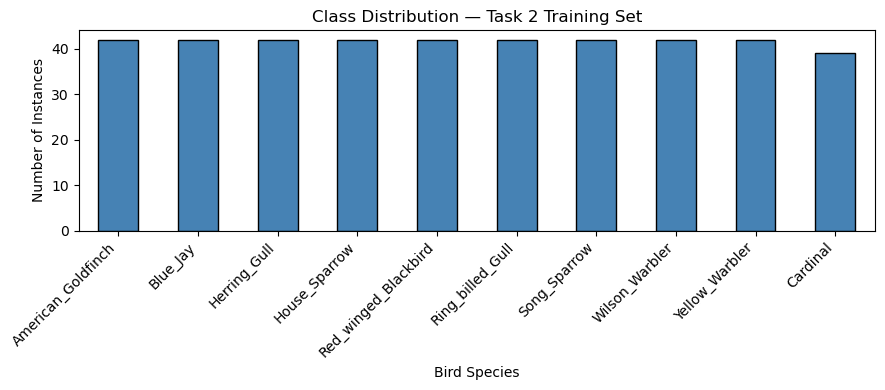

In [4]:
class_counts_t2 = train_meta_t2['class_name'].value_counts()
print(class_counts_t2)

class_counts_t2.plot(kind='bar', figsize=(9, 4), color='steelblue', edgecolor='black')
plt.title('Class Distribution — Task 2 Training Set')
plt.xlabel('Bird Species')
plt.ylabel('Number of Instances')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 2. Feature Preprocessing

In [5]:
def split_train_test(df):
    mask = df['image_id'].str.startswith('train')
    return df[mask].copy(), df[~mask].copy()

color_tr_t2, color_te_t2 = split_train_test(color_hist_t2)
hog_tr_t2,   hog_te_t2   = split_train_test(hog_pca_t2)
addl_tr_t2,  addl_te_t2  = split_train_test(addl_feats_t2)

train_feats_t2 = color_tr_t2.merge(hog_tr_t2, on='image_id').merge(addl_tr_t2, on='image_id')
test_feats_t2  = color_te_t2.merge(hog_te_t2, on='image_id').merge(addl_te_t2, on='image_id')

train_df_t2 = train_meta_t2.merge(train_feats_t2, on='image_id')
test_df_t2  = test_meta_t2.merge(test_feats_t2,   on='image_id')

print('train_df shape:', train_df_t2.shape)
print('test_df shape: ', test_df_t2.shape)

train_df shape: (417, 223)
test_df shape:  (180, 221)


In [6]:
feat_cols_t2  = [c for c in train_feats_t2.columns if c != 'image_id']
color_cols_t2 = [c for c in feat_cols_t2 if c.startswith('color')]
hog_cols_t2   = [c for c in feat_cols_t2 if c.startswith('hog')]
addl_cols_t2  = [c for c in feat_cols_t2 if c.startswith('feat')]

print(f'Features — colour: {len(color_cols_t2)}, HOG: {len(hog_cols_t2)}, additional: {len(addl_cols_t2)}, total: {len(feat_cols_t2)}')

X_t2      = train_df_t2[feat_cols_t2].values
y_t2      = train_df_t2['class_id'].values
X_test_t2 = test_df_t2[feat_cols_t2].values

class_names_t2 = train_meta_t2.groupby('class_id')['class_name'].first().sort_index().tolist()
print('Class names:', class_names_t2)

Features — colour: 96, HOG: 100, additional: 23, total: 219
Class names: ['American_Goldfinch', 'Blue_Jay', 'Cardinal', 'Herring_Gull', 'House_Sparrow', 'Red_winged_Blackbird', 'Ring_billed_Gull', 'Song_Sparrow', 'Wilson_Warbler', 'Yellow_Warbler']


In [7]:
scaler_t2 = StandardScaler()
X_scaled_t2      = scaler_t2.fit_transform(X_t2)
X_test_scaled_t2 = scaler_t2.transform(X_test_t2)

print('X_scaled shape:     ', X_scaled_t2.shape)
print('X_test_scaled shape:', X_test_scaled_t2.shape)

X_scaled shape:      (417, 219)
X_test_scaled shape: (180, 219)


## 3. Model Comparison via Cross-Validation (Provided Features)

In [8]:
cv_t2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=30027)

models_t2 = [
    ('Zero-R (Baseline)',   DummyClassifier(strategy='most_frequent')),
    ('SVM (RBF)',           SVC(kernel='rbf', C=10, gamma='scale', random_state=30027)),
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=30027)),
    ('Random Forest',       RandomForestClassifier(n_estimators=100, random_state=30027)),
]

results_t2 = {}
for name, model in models_t2:
    start  = time.time()
    scores = cross_val_score(model, X_scaled_t2, y_t2, cv=cv_t2, scoring='accuracy')
    elapsed = time.time() - start
    results_t2[name] = scores
    print(f'{name:<25} Accuracy: {scores.mean():.4f} +/- {scores.std():.4f}   (time: {elapsed:.1f}s)')

Zero-R (Baseline)         Accuracy: 0.0959 +/- 0.0006   (time: 0.0s)
SVM (RBF)                 Accuracy: 0.2182 +/- 0.0490   (time: 0.1s)
Logistic Regression       Accuracy: 0.2470 +/- 0.0193   (time: 0.1s)
Random Forest             Accuracy: 0.3405 +/- 0.0196   (time: 0.9s)


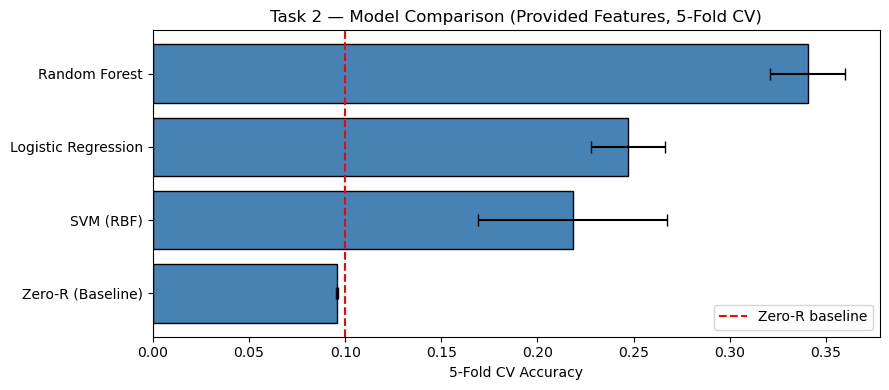

In [9]:
model_names_t2 = list(results_t2.keys())
mean_scores_t2 = [results_t2[n].mean() for n in model_names_t2]
std_scores_t2  = [results_t2[n].std()  for n in model_names_t2]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(model_names_t2, mean_scores_t2, xerr=std_scores_t2,
        color='steelblue', edgecolor='black', capsize=4)
ax.axvline(x=0.1, color='red', linestyle='--', label='Zero-R baseline')
ax.set_xlabel('5-Fold CV Accuracy')
ax.set_title('Task 2 — Model Comparison (Provided Features, 5-Fold CV)')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Feature Subset Analysis

In [10]:
feature_subsets_t2 = [
    ('Colour Histogram only', color_cols_t2),
    ('HOG (PCA) only',        hog_cols_t2),
    ('Additional only',       addl_cols_t2),
    ('All features combined', feat_cols_t2),
]

lr_t2 = LogisticRegression(max_iter=1000, random_state=30027)

print('Feature subset analysis — Logistic Regression, 5-fold CV')
print('-' * 55)
for label, cols in feature_subsets_t2:
    X_sub = StandardScaler().fit_transform(train_df_t2[cols].values)
    scores = cross_val_score(lr_t2, X_sub, y_t2, cv=cv_t2, scoring='accuracy')
    print(f'{label:<30}  Accuracy: {scores.mean():.4f} +/- {scores.std():.4f}')

Feature subset analysis — Logistic Regression, 5-fold CV
-------------------------------------------------------
Colour Histogram only           Accuracy: 0.2183 +/- 0.0329
HOG (PCA) only                  Accuracy: 0.2158 +/- 0.0245
Additional only                 Accuracy: 0.2926 +/- 0.0294
All features combined           Accuracy: 0.2470 +/- 0.0193


## 5. Error Analysis — Confusion Matrix (Provided Features)

In [12]:
X_tr_t2, X_val_t2, y_tr_t2, y_val_t2 = train_test_split(
    X_scaled_t2, y_t2, test_size=0.2, stratify=y_t2, random_state=30027
)

# Random Forest — best single model on Task 2 provided features
rf_eval_t2 = RandomForestClassifier(n_estimators=100, random_state=30027)
rf_eval_t2.fit(X_tr_t2, y_tr_t2)
y_pred_t2 = rf_eval_t2.predict(X_val_t2)

print('Holdout accuracy:', accuracy_score(y_val_t2, y_pred_t2))
print()
print(classification_report(y_val_t2, y_pred_t2, target_names=class_names_t2))

Holdout accuracy: 0.32142857142857145

                      precision    recall  f1-score   support

  American_Goldfinch       0.44      0.44      0.44         9
            Blue_Jay       0.41      0.78      0.54         9
            Cardinal       0.40      0.25      0.31         8
        Herring_Gull       0.10      0.12      0.11         8
       House_Sparrow       0.00      0.00      0.00         8
Red_winged_Blackbird       0.36      0.44      0.40         9
    Ring_billed_Gull       0.20      0.12      0.15         8
        Song_Sparrow       0.30      0.33      0.32         9
      Wilson_Warbler       0.50      0.38      0.43         8
      Yellow_Warbler       0.33      0.25      0.29         8

            accuracy                           0.32        84
           macro avg       0.31      0.31      0.30        84
        weighted avg       0.31      0.32      0.30        84



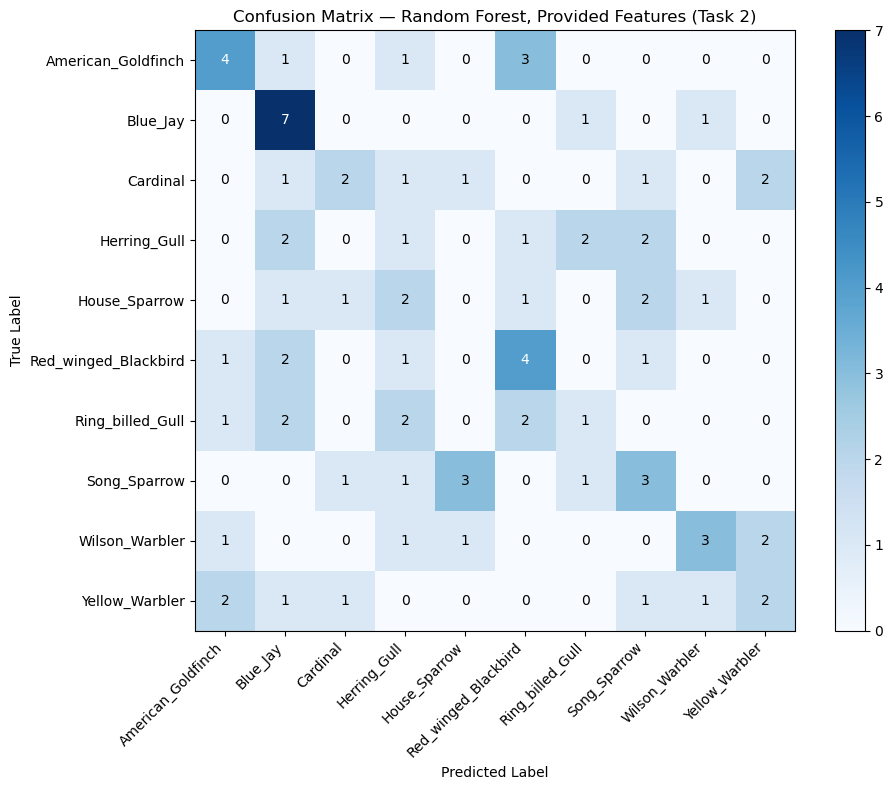

In [13]:
cm_t2 = confusion_matrix(y_val_t2, y_pred_t2)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm_t2, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(class_names_t2)))
ax.set_yticks(range(len(class_names_t2)))
ax.set_xticklabels(class_names_t2, rotation=45, ha='right')
ax.set_yticklabels(class_names_t2)
thresh = cm_t2.max() / 2.0
for i in range(cm_t2.shape[0]):
    for j in range(cm_t2.shape[1]):
        ax.text(j, i, str(cm_t2[i, j]), ha='center', va='center',
                color='white' if cm_t2[i, j] > thresh else 'black')
ax.set_ylabel('True Label')
ax.set_xlabel('Predicted Label')
ax.set_title('Confusion Matrix — Random Forest, Provided Features (Task 2)')
plt.tight_layout()
plt.show()

In [ ]:
per_class_acc_t2 = cm_t2.diagonal() / cm_t2.sum(axis=1)
for name, acc in zip(class_names_t2, per_class_acc_t2):
    print(f'{name:<25}: {acc:.2f}')

## 6. ResNet50 Feature Extraction



In [14]:
import sys
!{sys.executable} -m pip install torch torchvision --quiet

In [15]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import os

resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
feature_extractor = torch.nn.Sequential(*list(resnet.children())[:-1])
feature_extractor.eval()

transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

print('ResNet50 loaded. Output feature dimension: 2048')

ResNet50 loaded. Output feature dimension: 2048


In [17]:
DATA_DIR_T2 = 'data/task2_data/'

def extract_resnet_features(meta_df, base_dir, desc='Extracting'):
    features = []
    for i, row in meta_df.iterrows():
        img_path = os.path.join(base_dir, row['image_path'])
        try:
            img    = Image.open(img_path).convert('RGB')
            tensor = transform(img).unsqueeze(0)
            with torch.no_grad():
                feat = feature_extractor(tensor).squeeze().numpy()
            features.append(feat)
        except Exception as e:
            print(f'  WARNING: {img_path}: {e}')
            features.append(np.zeros(2048))
        if (i + 1) % 100 == 0 or (i + 1) == len(meta_df):
            print(f'  {desc}: {i + 1}/{len(meta_df)} done')
    return np.array(features)


t2_train_path = DATA_DIR_T2 + 'resnet50_train_features.npy'
t2_test_path  = DATA_DIR_T2 + 'resnet50_test_features.npy'

if os.path.exists(t2_train_path) and os.path.exists(t2_test_path):
    print('Loading saved ResNet50 features...')
    X_train_resnet_t2 = np.load(t2_train_path)
    X_test_resnet_t2  = np.load(t2_test_path)
else:
    print('Extracting features (2-5 mins on CPU)...')
    X_train_resnet_t2 = extract_resnet_features(train_meta_t2, DATA_DIR_T2, 'Train')
    X_test_resnet_t2  = extract_resnet_features(test_meta_t2,  DATA_DIR_T2, 'Test')
    np.save(t2_train_path, X_train_resnet_t2)
    np.save(t2_test_path,  X_test_resnet_t2)
    print('Saved for future runs.')

print(f'Train features: {X_train_resnet_t2.shape}')
print(f'Test features:  {X_test_resnet_t2.shape}')

Extracting features (2-5 mins on CPU)...
  Train: 100/417 done
  Train: 200/417 done
  Train: 300/417 done
  Train: 400/417 done
  Train: 417/417 done
  Test: 100/180 done
  Test: 180/180 done
Saved for future runs.
Train features: (417, 2048)
Test features:  (180, 2048)


## 7. Model Comparison — ResNet50 Features

In [18]:
scaler_r_t2 = StandardScaler()
X_r_scaled_t2      = scaler_r_t2.fit_transform(X_train_resnet_t2)
X_r_test_scaled_t2 = scaler_r_t2.transform(X_test_resnet_t2)

models_resnet_t2 = [
    ('Zero-R (Baseline)',   DummyClassifier(strategy='most_frequent')),
    ('SVM (RBF)',           SVC(kernel='rbf', C=10, gamma='scale', random_state=30027)),
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=30027)),
    ('Random Forest',       RandomForestClassifier(n_estimators=200, max_features='sqrt', random_state=30027)),
]

results_resnet_t2 = {}
print('Task 2 — ResNet50 Features (5-fold CV)')
print('-' * 55)
for name, model in models_resnet_t2:
    start  = time.time()
    scores = cross_val_score(model, X_r_scaled_t2, y_t2, cv=cv_t2, scoring='accuracy')
    elapsed = time.time() - start
    results_resnet_t2[name] = scores
    print(f'{name:<25} Accuracy: {scores.mean():.4f} +/- {scores.std():.4f}   (time: {elapsed:.1f}s)')

Task 2 — ResNet50 Features (5-fold CV)
-------------------------------------------------------
Zero-R (Baseline)         Accuracy: 0.0959 +/- 0.0006   (time: 0.0s)
SVM (RBF)                 Accuracy: 0.8585 +/- 0.0439   (time: 0.3s)
Logistic Regression       Accuracy: 0.8561 +/- 0.0330   (time: 0.5s)
Random Forest             Accuracy: 0.8705 +/- 0.0235   (time: 3.4s)


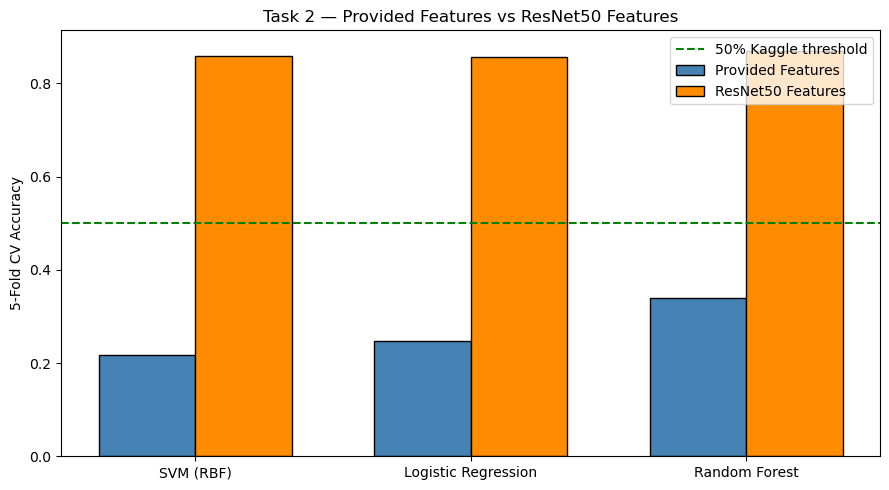

In [19]:
# Side-by-side: provided features vs ResNet50
compare_models_t2 = ['SVM (RBF)', 'Logistic Regression', 'Random Forest']
provided_acc_t2   = [results_t2[m].mean()        for m in compare_models_t2]
resnet_acc_t2     = [results_resnet_t2[m].mean() for m in compare_models_t2]

x = np.arange(len(compare_models_t2))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width/2, provided_acc_t2, width, label='Provided Features', color='steelblue',  edgecolor='black')
ax.bar(x + width/2, resnet_acc_t2,   width, label='ResNet50 Features', color='darkorange', edgecolor='black')
ax.axhline(y=0.5, color='green', linestyle='--', label='50% Kaggle threshold')
ax.set_xticks(x)
ax.set_xticklabels(compare_models_t2)
ax.set_ylabel('5-Fold CV Accuracy')
ax.set_title('Task 2 — Provided Features vs ResNet50 Features')
ax.legend()
plt.tight_layout()
plt.show()

## 8. Confusion Matrix — ResNet50 Features

In [21]:
X_tr_r_t2, X_val_r_t2, y_tr_r_t2, y_val_r_t2 = train_test_split(
    X_r_scaled_t2, y_t2, test_size=0.2, stratify=y_t2, random_state=30027
)

best_resnet_name_t2 = max(results_resnet_t2, key=lambda n: results_resnet_t2[n].mean())
print(f'Best model on ResNet features: {best_resnet_name_t2} ({results_resnet_t2[best_resnet_name_t2].mean():.4f})')

best_resnet_clf_t2 = dict(models_resnet_t2)[best_resnet_name_t2]
best_resnet_clf_t2.fit(X_tr_r_t2, y_tr_r_t2)
y_pred_r_t2 = best_resnet_clf_t2.predict(X_val_r_t2)

print('Holdout accuracy:', accuracy_score(y_val_r_t2, y_pred_r_t2))
print()
print(classification_report(y_val_r_t2, y_pred_r_t2, target_names=class_names_t2))

Best model on ResNet features: Random Forest (0.8705)
Holdout accuracy: 0.9047619047619048

                      precision    recall  f1-score   support

  American_Goldfinch       1.00      1.00      1.00         9
            Blue_Jay       1.00      1.00      1.00         9
            Cardinal       0.89      1.00      0.94         8
        Herring_Gull       0.86      0.75      0.80         8
       House_Sparrow       0.88      0.88      0.88         8
Red_winged_Blackbird       1.00      0.89      0.94         9
    Ring_billed_Gull       0.78      0.88      0.82         8
        Song_Sparrow       1.00      1.00      1.00         9
      Wilson_Warbler       1.00      0.62      0.77         8
      Yellow_Warbler       0.73      1.00      0.84         8

            accuracy                           0.90        84
           macro avg       0.91      0.90      0.90        84
        weighted avg       0.92      0.90      0.90        84



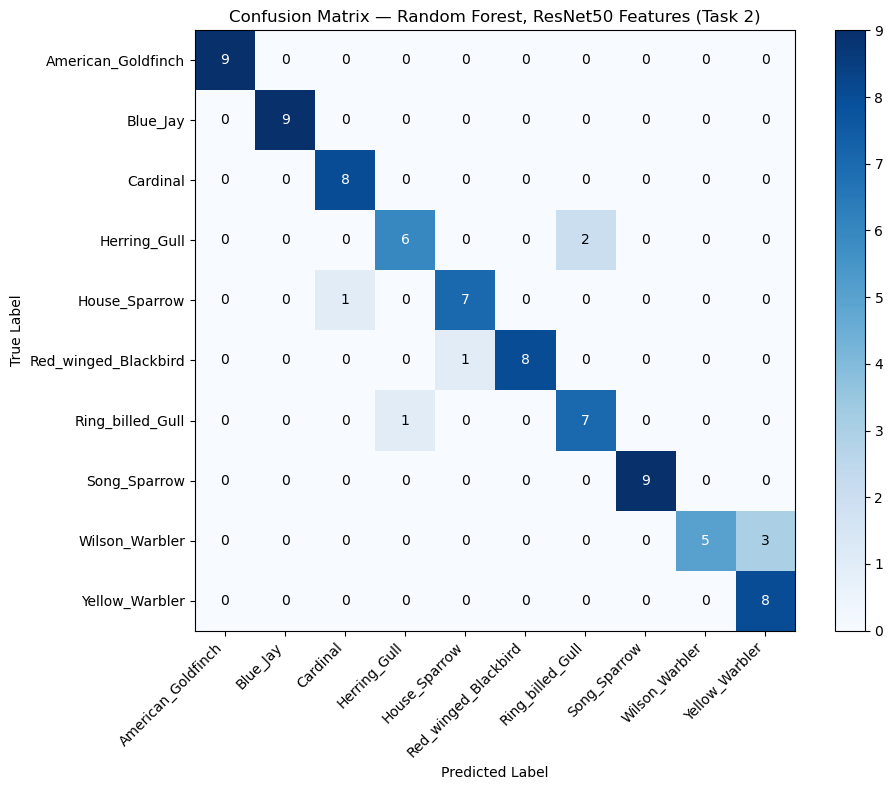

In [22]:
cm_r_t2 = confusion_matrix(y_val_r_t2, y_pred_r_t2)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm_r_t2, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(class_names_t2)))
ax.set_yticks(range(len(class_names_t2)))
ax.set_xticklabels(class_names_t2, rotation=45, ha='right')
ax.set_yticklabels(class_names_t2)
thresh = cm_r_t2.max() / 2.0
for i in range(cm_r_t2.shape[0]):
    for j in range(cm_r_t2.shape[1]):
        ax.text(j, i, str(cm_r_t2[i, j]), ha='center', va='center',
                color='white' if cm_r_t2[i, j] > thresh else 'black')
ax.set_ylabel('True Label')
ax.set_xlabel('Predicted Label')
ax.set_title(f'Confusion Matrix — {best_resnet_name_t2}, ResNet50 Features (Task 2)')
plt.tight_layout()
plt.show()

In [ ]:
per_class_acc_r_t2 = cm_r_t2.diagonal() / cm_r_t2.sum(axis=1)
for name, acc in zip(class_names_t2, per_class_acc_r_t2):
    print(f'{name:<25}: {acc:.2f}')

## 9. Generate Kaggle Submission (ResNet50 Features)

In [23]:
final_clf_t2 = dict(models_resnet_t2)[best_resnet_name_t2]
final_clf_t2.fit(X_r_scaled_t2, y_t2)
test_preds_t2 = final_clf_t2.predict(X_r_test_scaled_t2)

id_to_name_t2 = train_meta_t2.groupby('class_id')['class_name'].first().to_dict()

submission_t2 = pd.DataFrame({
    'image_id': test_df_t2['image_id'].values,
    'class_id': test_preds_t2
})
submission_t2['class_name'] = submission_t2['class_id'].map(id_to_name_t2)

print(f'Submission model: {best_resnet_name_t2} (ResNet50 features)')
print(submission_t2.head(10))
print()
print('Prediction distribution:')
print(submission_t2['class_name'].value_counts())

Submission model: Random Forest (ResNet50 features)
    image_id  class_id          class_name
0  test_0000         9      Yellow_Warbler
1  test_0001         2            Cardinal
2  test_0002         0  American_Goldfinch
3  test_0003         2            Cardinal
4  test_0004         0  American_Goldfinch
5  test_0005         2            Cardinal
6  test_0006         3        Herring_Gull
7  test_0007         6    Ring_billed_Gull
8  test_0008         3        Herring_Gull
9  test_0009         1            Blue_Jay

Prediction distribution:
class_name
Song_Sparrow            20
Yellow_Warbler          19
American_Goldfinch      19
Blue_Jay                19
Cardinal                18
Ring_billed_Gull        18
Red_winged_Blackbird    18
Herring_Gull            17
Wilson_Warbler          16
House_Sparrow           16
Name: count, dtype: int64


In [24]:
submission_t2[['image_id', 'class_id']].to_csv('task2_submission.csv', index=False)
print('Saved task2_submission.csv')

Saved task2_submission.csv
